# **NCR_Ride_Booking_Project**

# **Phase 1 - Data Cleaning**

In [ ]:
# RIDE BOOKINGS - DATA CLEANING (simple version)
# Step 1 - Import libraries and load the data
import pandas as pd
df = pd.read_csv("/content/ncr_ride_bookings.csv")   # change the path if needed

# Keep an untouched copy of the original, so we can always compare later
df_raw = df.copy()


# %% Step 2 - First look at the data
print("Rows and columns:", df.shape)
print()
print(df.columns.tolist())
df.head()


# %% Step 3 - Data types and non-null counts
df.info()


# %% Step 4 - Summary statistics
df.describe()


# %% Step 5 - Clean the column names
# "Booking Status" -> "booking_status"  (easier to type, works in SQL too)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())


# %% Step 6 - Remove the extra quotes from ID columns
# Raw IDs look like "CNR5884300" (with quotes inside the value)
print("Before:", df["booking_id"].iloc[0])

df["booking_id"] = df["booking_id"].str.replace('"', "", regex=False)
df["customer_id"] = df["customer_id"].str.replace('"', "", regex=False)

print("After :", df["booking_id"].iloc[0])


# %% Step 7 - Remove extra spaces from all text columns
text_columns = df.select_dtypes(exclude="number").columns

for col in text_columns:
    df[col] = df[col].str.strip()


# %% Step 8 - Fix date and time
# Join date + time into one datetime column
df["date"] = pd.to_datetime(df["date"])
df["booking_datetime"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d") + " " + df["time"]
)

# Create useful columns for analysis later
df["hour"] = df["booking_datetime"].dt.hour
df["day_name"] = df["booking_datetime"].dt.day_name()
df["month_name"] = df["booking_datetime"].dt.month_name()

df[["date", "time", "booking_datetime", "hour", "day_name"]].head()


# %% Step 9 - Check missing values
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})


# %% Step 10 - WHY are values missing?
# Many columns look "bad" but the nulls are expected:
# a cancelled ride has no rating, no payment method, no distance...
print(df["booking_status"].value_counts())
print()

# Count the nulls inside each booking status
cols_to_check = ["avg_vtat", "avg_ctat", "booking_value", "ride_distance",
                 "driver_ratings", "customer_rating", "payment_method"]

df.groupby("booking_status")[cols_to_check].agg(lambda x: x.isnull().sum())

# Reading the table: ratings, payment and distance are missing for every
# status except "Completed". So these are NOT errors - we keep them as NaN.


# %% Step 11 - Fill the text "reason" columns
# These columns are empty when the reason does not apply, so we label them.
reason_columns = ["reason_for_cancelling_by_customer",
                  "driver_cancellation_reason",
                  "incomplete_rides_reason"]

for col in reason_columns:
    df[col] = df[col].fillna("Not Applicable")


# %% Step 12 - Check duplicates
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate booking IDs:", df["booking_id"].duplicated().sum())

# Look at a few repeated IDs before deciding what to do
repeated = df[df["booking_id"].duplicated(keep=False)].sort_values("booking_id")
repeated[["booking_id", "customer_id", "date", "booking_status"]].head(6)

# Same ID but different customer and date = two different bookings
# (the ID repeated by chance), so we KEEP these rows.


# %% Step 13 - Check categories for spelling mistakes
for col in ["booking_status", "vehicle_type", "payment_method"]:
    print(df[col].value_counts(dropna=False))
    print()


# %% Step 14 - Check numbers for wrong values
# Negative values
number_columns = ["avg_vtat", "avg_ctat", "booking_value", "ride_distance"]
for col in number_columns:
    print(col, "-> negative values:", (df[col] < 0).sum())

# Ratings must be between 1 and 5
print("Driver ratings outside 1-5  :", (~df["driver_ratings"].dropna().between(1, 5)).sum())
print("Customer ratings outside 1-5:", (~df["customer_rating"].dropna().between(1, 5)).sum())

# Date range
print("Dates from", df["date"].min().date(), "to", df["date"].max().date())


# %% Step 15 - Final check
print("Before cleaning:", df_raw.shape)
print("After cleaning :", df.shape)
print()
df.info()


# %% Step 16 - Save the cleaned file
df.to_csv("/content/ride_bookings_cleaned.csv", index=False)
print("Saved!")

Rows and columns: (150000, 21)

['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 

# **Phase 2 - EDA**

In [ ]:
#Question 1: How big is the dataset?
import pandas as pd
df = pd.read_csv("/content/ride_bookings_cleaned.csv", parse_dates=["date"])

print("Total bookings   :", len(df))
print("First date       :", df["date"].min().date())
print("Last date        :", df["date"].max().date())
print("Unique customers :", df["customer_id"].nunique())
print("Pickup locations :", df["pickup_location"].nunique())
print("Vehicle types    :", df["vehicle_type"].nunique())

Total bookings   : 150000
First date       : 2024-01-01
Last date        : 2024-12-30
Unique customers : 148788
Pickup locations : 176
Vehicle types    : 7


                       bookings  percent
booking_status                          
Completed                 93000     62.0
Cancelled by Driver       27000     18.0
No Driver Found           10500      7.0
Cancelled by Customer     10500      7.0
Incomplete                 9000      6.0


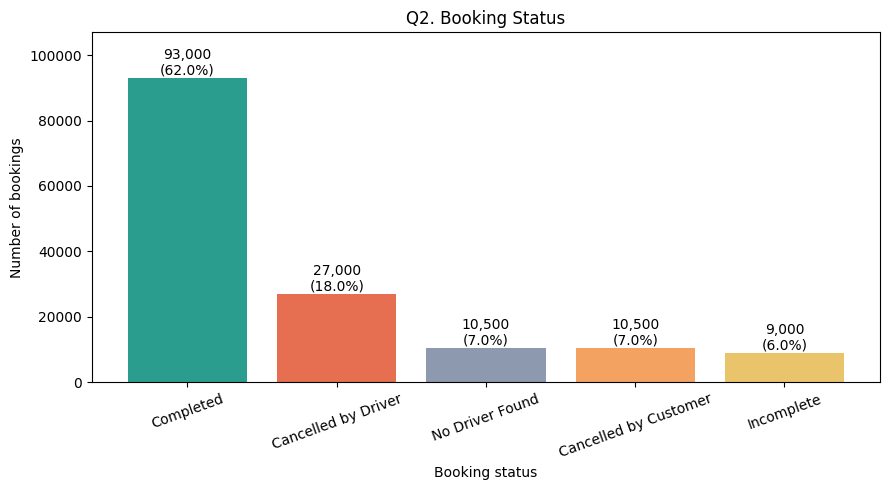

In [ ]:
#Question 2: How do bookings end?
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/ride_bookings_cleaned.csv", parse_dates=["date"])

# 1. Count each status, and calculate the percentage
status_count = df["booking_status"].value_counts()
status_percent = (df["booking_status"].value_counts(normalize=True) * 100).round(2)

summary = pd.DataFrame({"bookings": status_count, "percent": status_percent})
print(summary)

# 2. Bar chart with data labels
colors = ["#2a9d8f", "#e76f51", "#8d99ae", "#f4a261", "#e9c46a"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(status_count.index, status_count.values, color=colors)
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(status_count.values, status_percent.values)])
ax.set_title("Q2. Booking Status")
ax.set_xlabel("Booking status")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, status_count.max() * 1.15)   # leaves space for the labels
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
#Question 3: What are the completion rate and the unsuccessful rate?
total = len(df)

completed = (df["booking_status"] == "Completed").sum()
unsuccessful = (df["booking_status"] != "Completed").sum()
cancelled = df["booking_status"].isin(["Cancelled by Driver", "Cancelled by Customer"]).sum()

print("Total bookings        :", total)
print("Completed             :", completed, "->", round(completed / total * 100, 2), "%")
print("Unsuccessful          :", unsuccessful, "->", round(unsuccessful / total * 100, 2), "%")
print("Cancelled (any side)  :", cancelled, "->", round(cancelled / total * 100, 2), "%")

Total bookings        : 150000
Completed             : 93000 -> 62.0 %
Unsuccessful          : 57000 -> 38.0 %
Cancelled (any side)  : 37500 -> 25.0 %


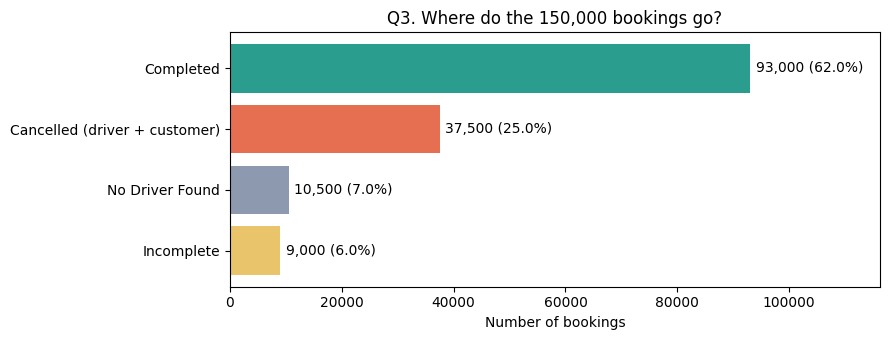

In [ ]:
#visualize
import matplotlib.pyplot as plt

# Group the 5 statuses into 4 business groups
groups = pd.Series({
    "Completed": completed,
    "Cancelled (driver + customer)": cancelled,
    "No Driver Found": (df["booking_status"] == "No Driver Found").sum(),
    "Incomplete": (df["booking_status"] == "Incomplete").sum(),
})

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(groups.index[::-1], groups.values[::-1],
               color=["#e9c46a", "#8d99ae", "#e76f51", "#2a9d8f"])
ax.bar_label(bars, labels=[f"{v:,} ({v/total*100:.1f}%)" for v in groups.values[::-1]], padding=4)
ax.set_xlim(0, groups.max() * 1.25)
ax.set_title("Q3. Where do the 150,000 bookings go?")
ax.set_xlabel("Number of bookings")
plt.tight_layout()
plt.show()

                       cancellations  share_of_cancellations_%  \
booking_status                                                   
Cancelled by Driver            27000                      72.0   
Cancelled by Customer          10500                      28.0   

                       share_of_all_bookings_%  
booking_status                                  
Cancelled by Driver                       18.0  
Cancelled by Customer                      7.0  
Drivers cancel 2.57 times more than customers


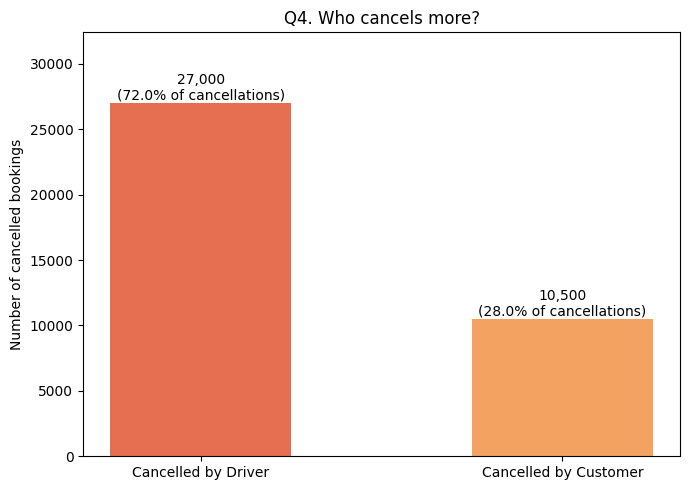

In [ ]:
#Question 4: Who cancels more, drivers or customers?
import pandas as pd
import matplotlib.pyplot as plt

total = len(df)

# 1. Keep only the cancelled bookings
cancelled_df = df[df["booking_status"].isin(["Cancelled by Driver", "Cancelled by Customer"])]

# 2. Count and compare
cancel_count = cancelled_df["booking_status"].value_counts()
cancel_share = (cancel_count / cancel_count.sum() * 100).round(1)   # share of all cancellations
pct_of_all = (cancel_count / total * 100).round(1)                  # share of all bookings

print(pd.DataFrame({
    "cancellations": cancel_count,
    "share_of_cancellations_%": cancel_share,
    "share_of_all_bookings_%": pct_of_all,
}))

ratio = cancel_count["Cancelled by Driver"] / cancel_count["Cancelled by Customer"]
print("Drivers cancel", round(ratio, 2), "times more than customers")

# 3. Chart
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(cancel_count.index, cancel_count.values, color=["#e76f51", "#f4a261"], width=0.5)
ax.bar_label(bars, labels=[f"{v:,}\n({s}% of cancellations)"
                           for v, s in zip(cancel_count.values, cancel_share.values)])
ax.set_ylim(0, cancel_count.max() * 1.2)
ax.set_title("Q4. Who cancels more?")
ax.set_ylabel("Number of cancelled bookings")
plt.tight_layout()
plt.show()

Customer cancellations: 10500
                                              bookings  percent
reason_for_cancelling_by_customer                              
Wrong Address                                     2362     22.5
Change of plans                                   2353     22.4
Driver is not moving towards pickup location      2335     22.2
Driver asked to cancel                            2295     21.9
AC is not working                                 1155     11.0


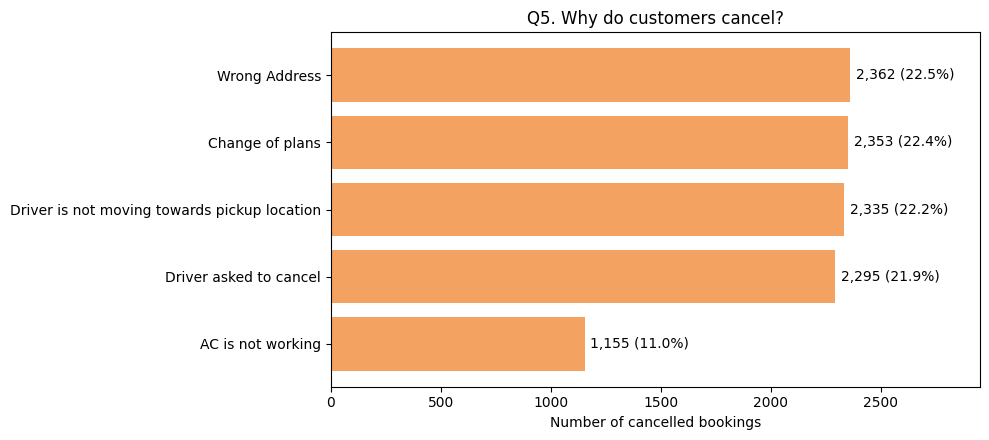

In [ ]:
#Question 5: Why do customers cancel?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep only bookings cancelled by the customer
cust_cancel = df[df["booking_status"] == "Cancelled by Customer"]
print("Customer cancellations:", len(cust_cancel))

# 2. Count each reason, and calculate the percentage
reason_count = cust_cancel["reason_for_cancelling_by_customer"].value_counts()
reason_pct = (reason_count / reason_count.sum() * 100).round(1)
print(pd.DataFrame({"bookings": reason_count, "percent": reason_pct}))

# 3. Sort small to large so the biggest bar is at the top of the chart
reason_count = reason_count.sort_values()
reason_pct = reason_pct[reason_count.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(reason_count.index, reason_count.values, color="#f4a261")
ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(reason_count.values, reason_pct.values)],
             padding=4)
ax.set_xlim(0, reason_count.max() * 1.25)
ax.set_title("Q5. Why do customers cancel?")
ax.set_xlabel("Number of cancelled bookings")
plt.tight_layout()
plt.show()

Driver cancellations: 27000
                                     bookings  percent
driver_cancellation_reason                            
Customer related issue                   6837     25.3
The customer was coughing/sick           6751     25.0
Personal & Car related issues            6726     24.9
More than permitted people in there      6686     24.8


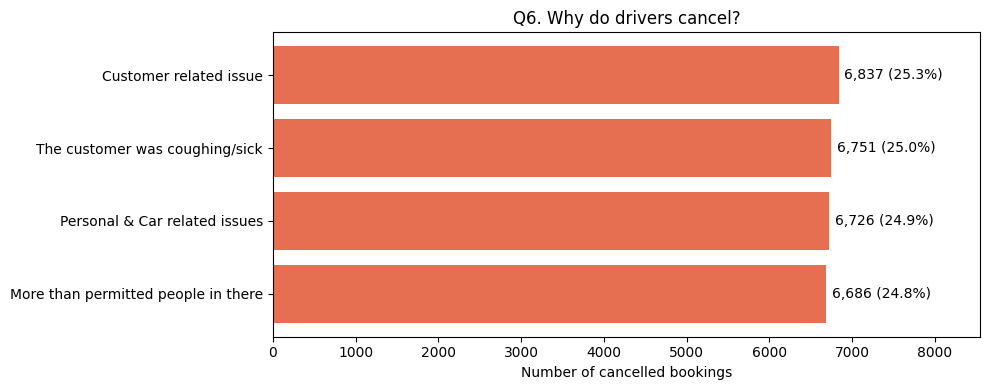

In [ ]:
#Question 6: Why do drivers cancel?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep only bookings cancelled by the driver
driver_cancel = df[df["booking_status"] == "Cancelled by Driver"]
print("Driver cancellations:", len(driver_cancel))

# 2. Count each reason, and calculate the percentage
reason_count = driver_cancel["driver_cancellation_reason"].value_counts()
reason_pct = (reason_count / reason_count.sum() * 100).round(1)
print(pd.DataFrame({"bookings": reason_count, "percent": reason_pct}))

# 3. Sort small to large so the biggest bar is at the top
reason_count = reason_count.sort_values()
reason_pct = reason_pct[reason_count.index]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(reason_count.index, reason_count.values, color="#e76f51")
ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(reason_count.values, reason_pct.values)],
             padding=4)
ax.set_xlim(0, reason_count.max() * 1.25)
ax.set_title("Q6. Why do drivers cancel?")
ax.set_xlabel("Number of cancelled bookings")
plt.tight_layout()
plt.show()

Incomplete rides: 9000
                         bookings  percent
incomplete_rides_reason                   
Customer Demand              3040     33.8
Vehicle Breakdown            3012     33.5
Other Issue                  2948     32.8


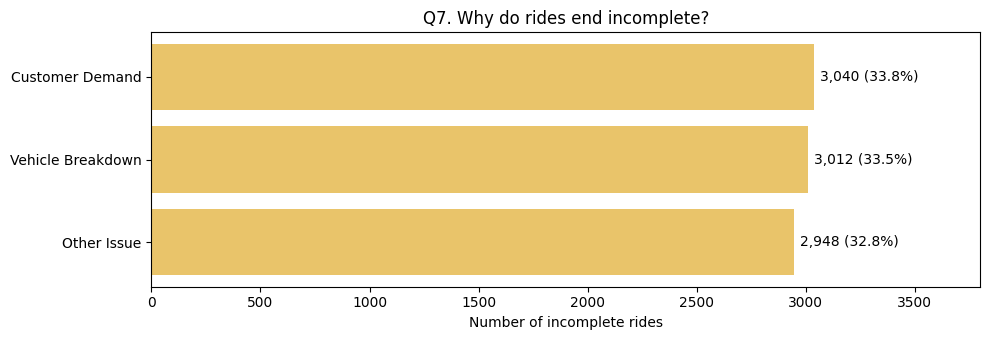

Booking value of incomplete rides: 4585609.0


In [ ]:
#Question 7: Why do rides end incomplete?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep only incomplete rides
incomplete = df[df["booking_status"] == "Incomplete"]
print("Incomplete rides:", len(incomplete))

# 2. Count each reason, and calculate the percentage
reason_count = incomplete["incomplete_rides_reason"].value_counts()
reason_pct = (reason_count / reason_count.sum() * 100).round(1)
print(pd.DataFrame({"bookings": reason_count, "percent": reason_pct}))

# 3. Sort small to large so the biggest bar is at the top
reason_count = reason_count.sort_values()
reason_pct = reason_pct[reason_count.index]

fig, ax = plt.subplots(figsize=(10, 3.5))
bars = ax.barh(reason_count.index, reason_count.values, color="#e9c46a")
ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(reason_count.values, reason_pct.values)],
             padding=4)
ax.set_xlim(0, reason_count.max() * 1.25)
ax.set_title("Q7. Why do rides end incomplete?")
ax.set_xlabel("Number of incomplete rides")
plt.tight_layout()
plt.show()

# 4. Bonus: how much booking value is tied to incomplete rides?
print("Booking value of incomplete rides:", incomplete["booking_value"].sum())

hour
0      1373
1      1360
2      1339
3      1383
4      1321
5      2786
6      4160
7      5450
8      6861
9      8234
10     9577
11     8390
12     7006
13     5470
14     7031
15     8202
16     9633
17    11044
18    12397
19    11047
20     9630
21     8103
22     5441
23     2762
Name: count, dtype: int64


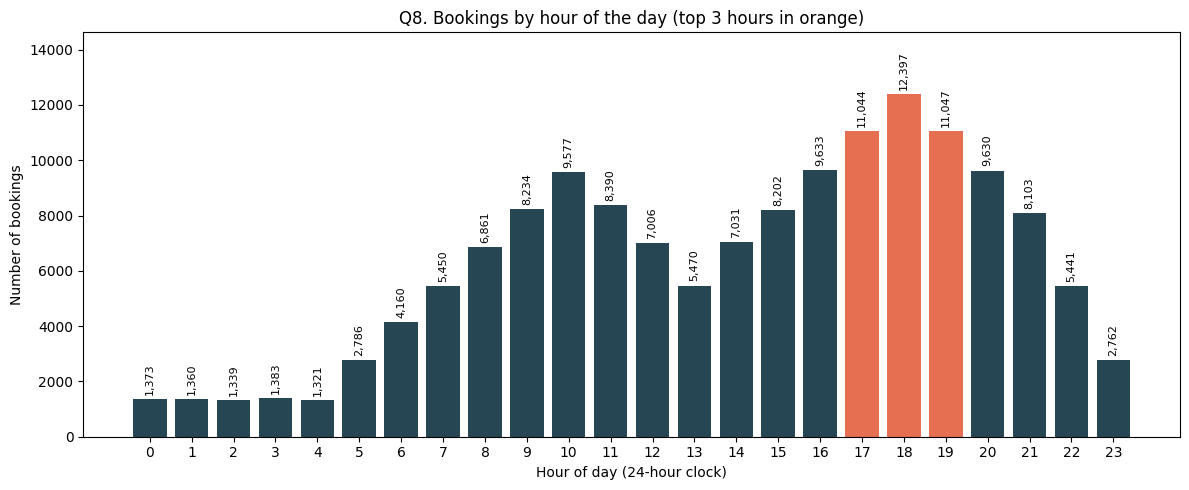

In [ ]:
#Question 8: Which hours of the day have the most bookings?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Count bookings for each hour, in hour order (0 to 23)
hourly = df["hour"].value_counts().sort_index()
print(hourly)

# 2. Find the top 3 hours and colour them orange
top3 = hourly.nlargest(3).index
colors = ["#e76f51" if h in top3 else "#264653" for h in hourly.index]

# 3. Bar chart with data labels
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(hourly.index, hourly.values, color=colors)
ax.bar_label(bars, labels=[f"{v:,}" for v in hourly.values], fontsize=8, rotation=90, padding=3)
ax.set_xticks(range(24))
ax.set_ylim(0, hourly.max() * 1.18)
ax.set_title("Q8. Bookings by hour of the day (top 3 hours in orange)")
ax.set_xlabel("Hour of day (24-hour clock)")
ax.set_ylabel("Number of bookings")
plt.tight_layout()
plt.show()

day_name
Monday       21644
Tuesday      21391
Wednesday    21413
Thursday     21215
Friday       21397
Saturday     21542
Sunday       21398
Name: count, dtype: int64
Busiest: Monday 21644
Quietest: Thursday 21215
          bookings  days  avg_per_day
day_type                             
Weekday     107060   261        410.0
Weekend      42940   104        413.0


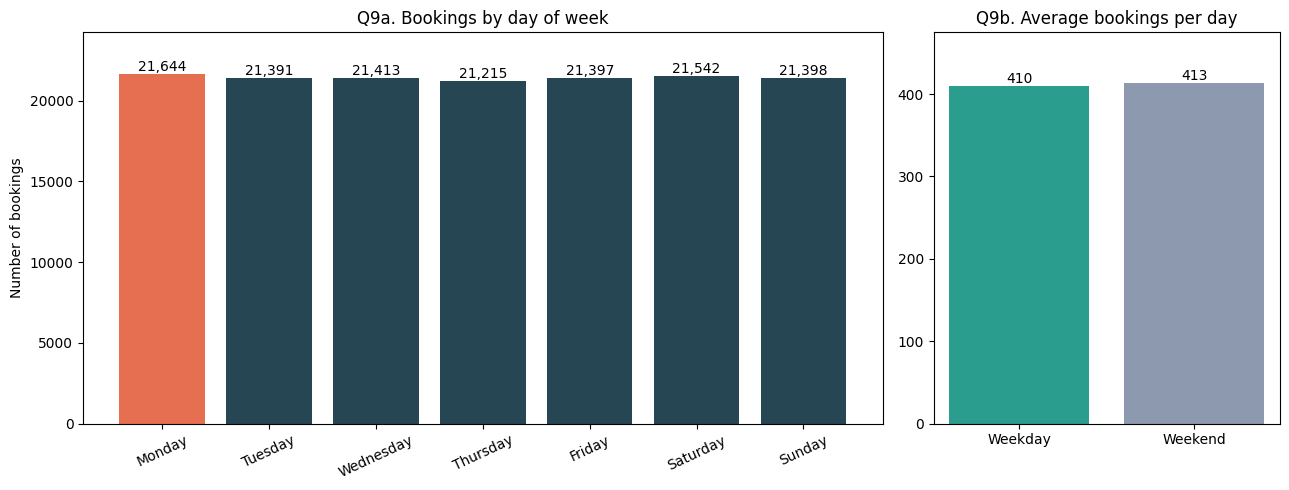

In [ ]:
# Question 9: Which day is busiest, and weekday versus weekend?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Bookings for each day of the week, in calendar order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = df["day_name"].value_counts().reindex(day_order)
print(daily)
print("Busiest:", daily.idxmax(), daily.max())
print("Quietest:", daily.idxmin(), daily.min())

# 2. Weekday vs weekend
df["day_type"] = df["day_name"].isin(["Saturday", "Sunday"]).map({True: "Weekend", False: "Weekday"})

bookings = df["day_type"].value_counts()
num_days = df.groupby("day_type")["date"].nunique()   # how many calendar days of each type
avg_per_day = (bookings / num_days).round(0)
print(pd.DataFrame({"bookings": bookings, "days": num_days, "avg_per_day": avg_per_day}))

# 3. Two charts side by side
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 1.3]})

colors = ["#e76f51" if d == daily.idxmax() else "#264653" for d in daily.index]
bars = ax[0].bar(daily.index, daily.values, color=colors)
ax[0].bar_label(bars, labels=[f"{v:,}" for v in daily.values])
ax[0].set_ylim(0, daily.max() * 1.12)
ax[0].set_title("Q9a. Bookings by day of week")
ax[0].set_ylabel("Number of bookings")
ax[0].tick_params(axis="x", rotation=25)

bars2 = ax[1].bar(avg_per_day.index, avg_per_day.values, color=["#2a9d8f", "#8d99ae"])
ax[1].bar_label(bars2, labels=[f"{v:,.0f}" for v in avg_per_day.values])
ax[1].set_ylim(0, avg_per_day.max() * 1.15)
ax[1].set_title("Q9b. Average bookings per day")

plt.tight_layout()
plt.show()

month_name
January      12861
February     11927
March        12719
April        12199
May          12778
June         12440
July         12897
August       12636
September    12248
October      12651
November     12394
December     12250
Name: count, dtype: int64
Busiest: July 12897
Quietest: February 11927
month_name
January      415.0
February     411.0
March        410.0
April        407.0
May          412.0
June         415.0
July         416.0
August       408.0
September    408.0
October      408.0
November     413.0
December     408.0
dtype: float64


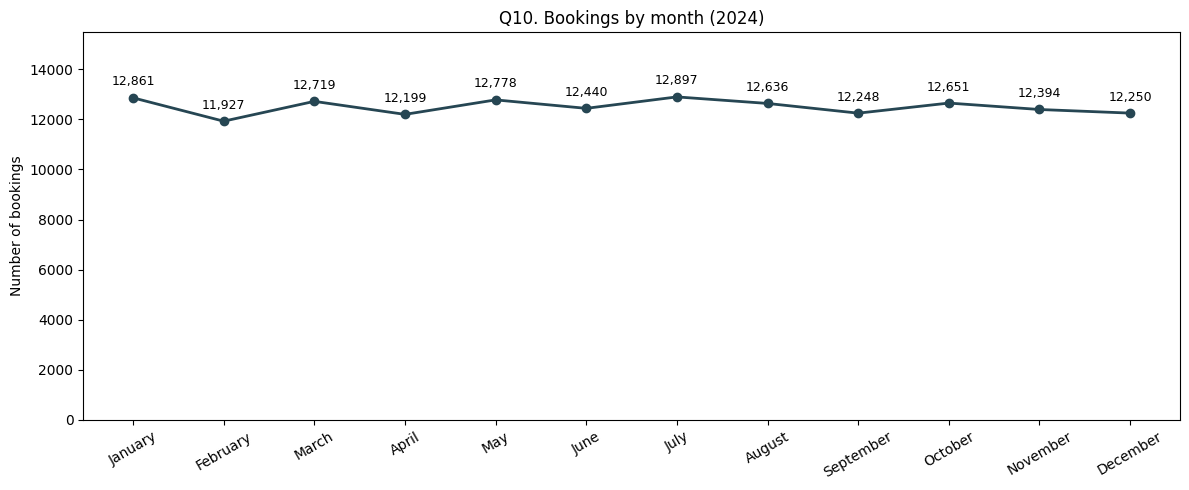

In [ ]:
#Question 10: How do bookings change month by month?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Bookings per month, in calendar order
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
monthly = df["month_name"].value_counts().reindex(month_order)
print(monthly)
print("Busiest:", monthly.idxmax(), monthly.max())
print("Quietest:", monthly.idxmin(), monthly.min())

# 2. Fair comparison: months have different lengths, so look at bookings PER DAY
days_in_data = df.groupby("month_name")["date"].nunique().reindex(month_order)
avg_per_day = (monthly / days_in_data).round(0)
print(avg_per_day)

# 3. Line chart with data labels
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, marker="o", color="#264653", linewidth=2)
for x, y in zip(monthly.index, monthly.values):
    ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_ylim(0, monthly.max() * 1.2)
ax.set_title("Q10. Bookings by month (2024)")
ax.set_ylabel("Number of bookings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

      completed  cancelled  driver_cancelled
hour                                        
0          62.5       24.8              18.1
1          60.9       25.3              18.4
2          63.7       22.2              16.6
3          62.2       25.7              19.0
4          62.8       25.6              18.2
5          61.6       26.4              19.1
6          62.7       24.2              16.8
7          61.4       25.4              18.5
8          62.2       25.0              17.8
9          61.7       24.9              18.1
10         62.5       24.9              17.9
11         62.6       24.1              17.4
12         61.9       24.7              17.9
13         61.7       25.2              18.3
14         61.3       26.1              18.6
15         61.7       25.7              17.9
16         62.0       24.5              17.9
17         62.1       24.9              18.1
18         61.4       25.4              18.2
19         61.5       25.5              18.1
20        

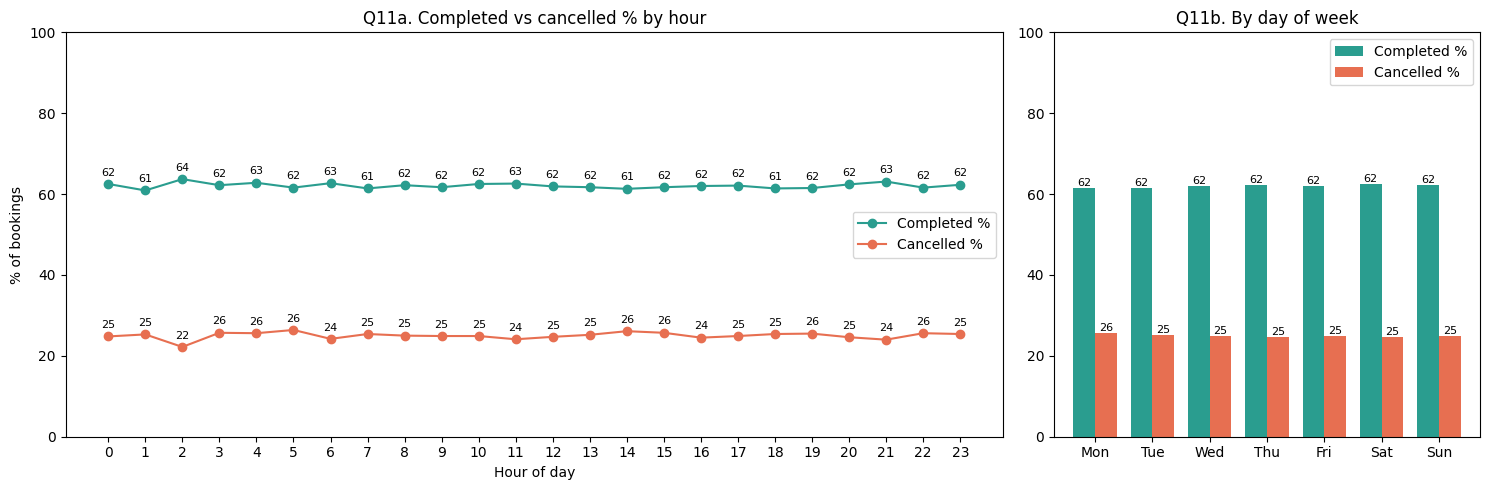

In [ ]:
#Question 11: Do completion and cancellation rates change by hour or day?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create True/False columns (True counts as 1, so the average becomes a percentage)
df["completed"] = df["booking_status"] == "Completed"
df["cancelled"] = df["booking_status"].isin(["Cancelled by Driver", "Cancelled by Customer"])
df["driver_cancelled"] = df["booking_status"] == "Cancelled by Driver"

# 2. Rate by hour
by_hour = (df.groupby("hour")[["completed", "cancelled", "driver_cancelled"]].mean() * 100).round(1)
print(by_hour)

# 3. Rate by day of week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = (df.groupby("day_name")[["completed", "cancelled"]].mean() * 100).round(1).reindex(day_order)
print(by_day)

# 4. Charts: by hour (left) and by day (right)
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})

ax[0].plot(by_hour.index, by_hour["completed"], marker="o", color="#2a9d8f", label="Completed %")
ax[0].plot(by_hour.index, by_hour["cancelled"], marker="o", color="#e76f51", label="Cancelled %")
for h, v in by_hour["completed"].items():
    ax[0].annotate(f"{v:.0f}", (h, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
for h, v in by_hour["cancelled"].items():
    ax[0].annotate(f"{v:.0f}", (h, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax[0].set_ylim(0, 100)
ax[0].set_xticks(range(24))
ax[0].set_title("Q11a. Completed vs cancelled % by hour")
ax[0].set_xlabel("Hour of day")
ax[0].set_ylabel("% of bookings")
ax[0].legend(loc="center right")

x = range(len(by_day)); w = 0.38
b1 = ax[1].bar([i - w/2 for i in x], by_day["completed"], w, color="#2a9d8f", label="Completed %")
b2 = ax[1].bar([i + w/2 for i in x], by_day["cancelled"], w, color="#e76f51", label="Cancelled %")
ax[1].bar_label(b1, fmt="%.0f", fontsize=8)
ax[1].bar_label(b2, fmt="%.0f", fontsize=8)
ax[1].set_xticks(list(x))
ax[1].set_xticklabels([d[:3] for d in by_day.index])
ax[1].set_ylim(0, 100)
ax[1].set_title("Q11b. By day of week")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

               bookings  percent
vehicle_type                    
Auto              37419     24.9
Go Mini           29806     19.9
Go Sedan          27141     18.1
Bike              22517     15.0
Premier Sedan     18111     12.1
eBike             10557      7.0
Uber XL            4449      3.0


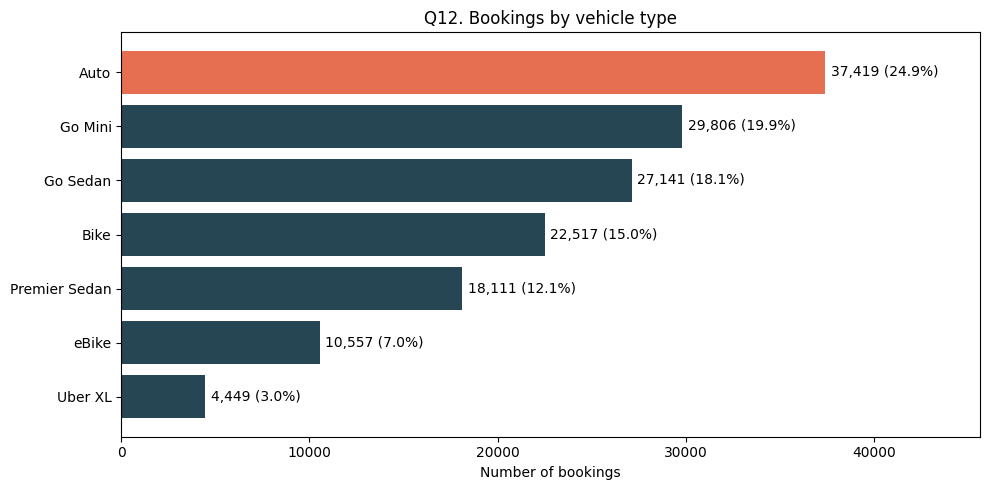

In [ ]:
#Question 12: Which vehicle type is booked the most?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Count and percentage for each vehicle type
vehicle_count = df["vehicle_type"].value_counts()
vehicle_pct = (df["vehicle_type"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"bookings": vehicle_count, "percent": vehicle_pct}))

# 2. Sort small to large so the biggest bar is at the top, and highlight it
vehicle_count = vehicle_count.sort_values()
vehicle_pct = vehicle_pct[vehicle_count.index]
colors = ["#e76f51" if v == vehicle_count.max() else "#264653" for v in vehicle_count.values]

# 3. Bar chart with data labels
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(vehicle_count.index, vehicle_count.values, color=colors)
ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(vehicle_count.values, vehicle_pct.values)],
             padding=4)
ax.set_xlim(0, vehicle_count.max() * 1.22)
ax.set_title("Q12. Bookings by vehicle type")
ax.set_xlabel("Number of bookings")
plt.tight_layout()
plt.show()

               bookings  completion_rate  cancel_rate
vehicle_type                                         
Uber XL            4449             62.6         24.5
Bike              22517             62.3         25.1
Go Mini           29806             62.2         24.9
eBike             10557             62.1         24.9
Premier Sedan     18111             62.1         24.9
Auto              37419             61.9         24.9
Go Sedan          27141             61.4         25.3
Best : Uber XL 62.6
Worst: Go Sedan 61.4
Gap between best and worst: 1.2 points


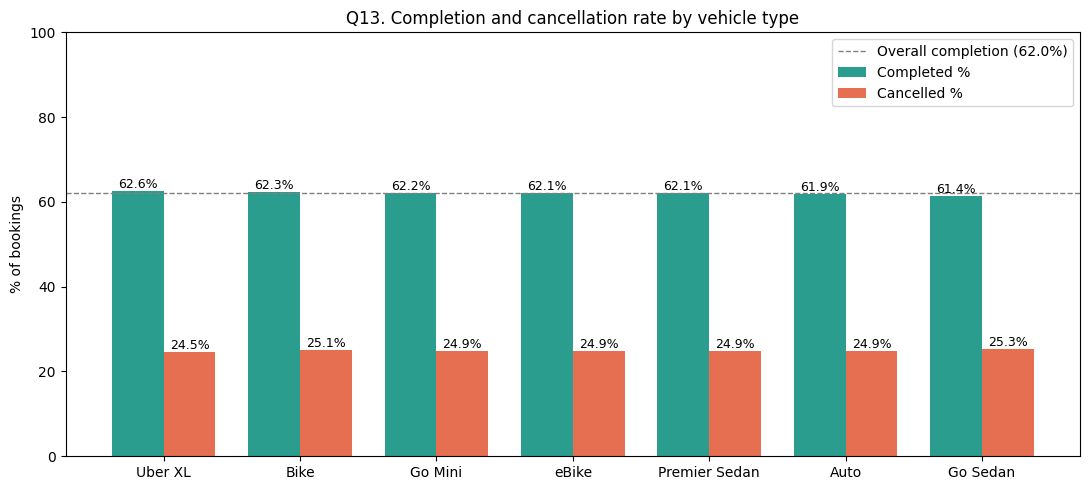

In [ ]:
#Question 13: Which vehicle type has the best and worst completion rate?
import pandas as pd
import matplotlib.pyplot as plt

# 1. True/False columns (same trick as Q11)
df["completed"] = df["booking_status"] == "Completed"
df["cancelled"] = df["booking_status"].isin(["Cancelled by Driver", "Cancelled by Customer"])

# 2. Rates for each vehicle type
vehicle = df.groupby("vehicle_type").agg(
    bookings=("booking_id", "count"),
    completion_rate=("completed", "mean"),
    cancel_rate=("cancelled", "mean"),
)
vehicle["completion_rate"] = (vehicle["completion_rate"] * 100).round(1)
vehicle["cancel_rate"] = (vehicle["cancel_rate"] * 100).round(1)
vehicle = vehicle.sort_values("completion_rate", ascending=False)
print(vehicle)

overall = df["completed"].mean() * 100
print("Best :", vehicle.index[0], vehicle["completion_rate"].iloc[0])
print("Worst:", vehicle.index[-1], vehicle["completion_rate"].iloc[-1])
print("Gap between best and worst:", round(vehicle["completion_rate"].max() - vehicle["completion_rate"].min(), 1), "points")

# 3. Grouped bar chart with data labels
fig, ax = plt.subplots(figsize=(11, 5))
x = range(len(vehicle)); w = 0.38
b1 = ax.bar([i - w/2 for i in x], vehicle["completion_rate"], w, color="#2a9d8f", label="Completed %")
b2 = ax.bar([i + w/2 for i in x], vehicle["cancel_rate"], w, color="#e76f51", label="Cancelled %")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9)
ax.bar_label(b2, fmt="%.1f%%", fontsize=9)
ax.axhline(overall, color="gray", linestyle="--", linewidth=1, label=f"Overall completion ({overall:.1f}%)")
ax.set_xticks(list(x))
ax.set_xticklabels(vehicle.index)
ax.set_ylim(0, 100)
ax.set_title("Q13. Completion and cancellation rate by vehicle type")
ax.set_ylabel("% of bookings")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

Completed rides: 93000
Missing booking value: 0
               rides     revenue  avg_fare  revenue_share_%
vehicle_type                                               
Auto           23155  11727615.0     506.5             24.8
Go Mini        18549   9411418.0     507.4             19.9
Go Sedan       16676   8538560.0     512.0             18.1
Bike           14034   7144913.0     509.1             15.1
Premier Sedan  11252   5733655.0     509.6             12.1
eBike           6551   3298157.0     503.5              7.0
Uber XL         2783   1406256.0     505.3              3.0
Total revenue: 47260574.0


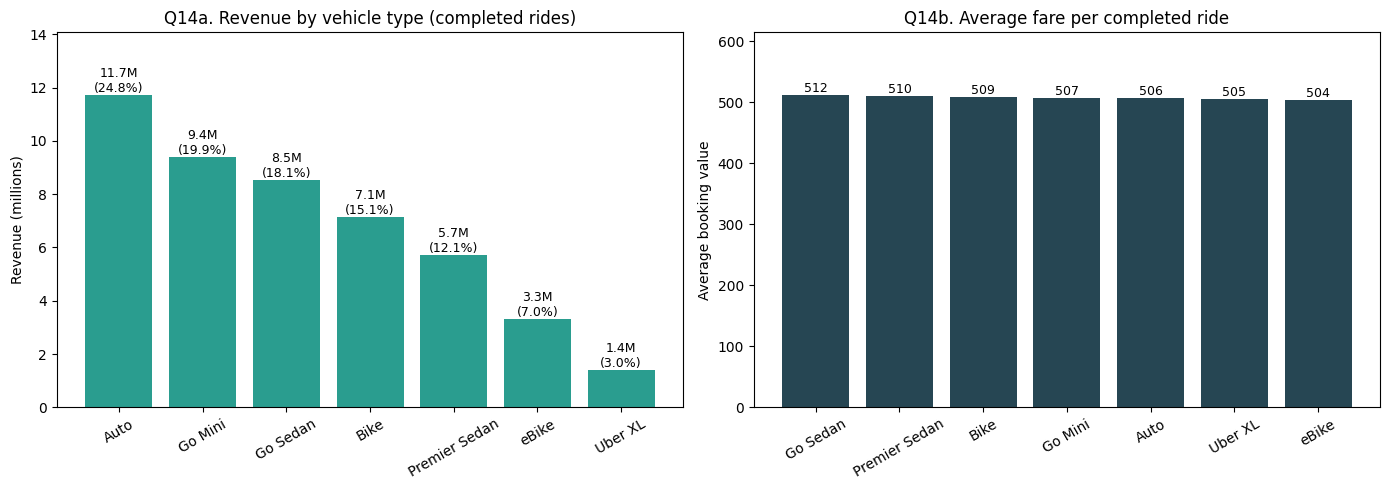

In [ ]:
# Question 14: Which vehicle type earns the most revenue, and what is the average fare?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep only completed rides
completed = df[df["booking_status"] == "Completed"]
print("Completed rides:", len(completed))
print("Missing booking value:", completed["booking_value"].isnull().sum())   # should be 0

# 2. Rides, revenue and average fare for each vehicle type
vehicle = completed.groupby("vehicle_type").agg(
    rides=("booking_id", "count"),
    revenue=("booking_value", "sum"),
    avg_fare=("booking_value", "mean"),
)
vehicle["revenue_share_%"] = (vehicle["revenue"] / vehicle["revenue"].sum() * 100).round(1)
vehicle["avg_fare"] = vehicle["avg_fare"].round(1)
vehicle = vehicle.sort_values("revenue", ascending=False)
print(vehicle)
print("Total revenue:", vehicle["revenue"].sum())

# 3. Two charts: revenue (left) and average fare (right)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

rev_m = vehicle["revenue"] / 1_000_000          # show in millions
bars = ax[0].bar(vehicle.index, rev_m.values, color="#2a9d8f")
ax[0].bar_label(bars, labels=[f"{v:.1f}M\n({p}%)" for v, p in zip(rev_m.values, vehicle["revenue_share_%"].values)],
                fontsize=9)
ax[0].set_ylim(0, rev_m.max() * 1.2)
ax[0].set_title("Q14a. Revenue by vehicle type (completed rides)")
ax[0].set_ylabel("Revenue (millions)")
ax[0].tick_params(axis="x", rotation=30)

fare = vehicle["avg_fare"].sort_values(ascending=False)
bars2 = ax[1].bar(fare.index, fare.values, color="#264653")
ax[1].bar_label(bars2, fmt="%.0f", fontsize=9)
ax[1].set_ylim(0, fare.max() * 1.2)
ax[1].set_title("Q14b. Average fare per completed ride")
ax[1].set_ylabel("Average booking value")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

               ride_distance  avg_vtat  avg_ctat
vehicle_type                                    
eBike                   25.0       8.5      29.2
Bike                    24.6       8.5      29.2
Auto                    24.6       8.4      29.1
Go Mini                 24.6       8.5      29.2
Go Sedan                24.6       8.4      29.0
Premier Sedan           24.6       8.4      29.2
Uber XL                 24.4       8.6      29.2
Overall: {'ride_distance': 24.6, 'avg_vtat': 8.5, 'avg_ctat': 29.1}


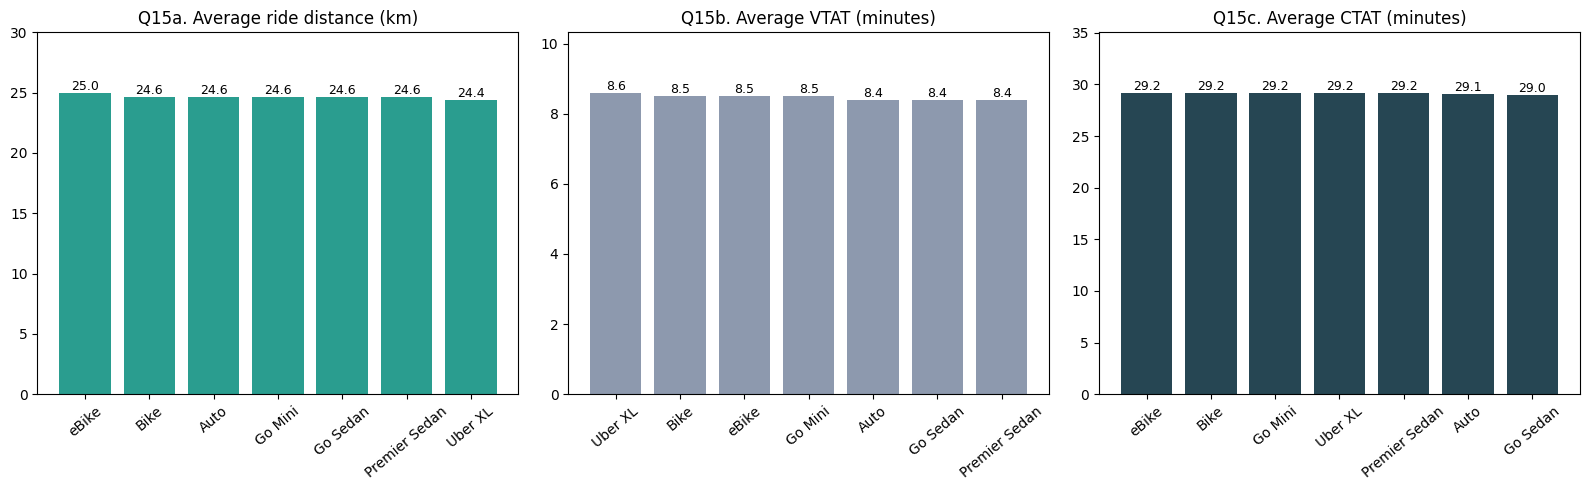

In [ ]:
#Question 15: How do distance and waiting times differ by vehicle type?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Average of the three columns for each vehicle type
stats = df.groupby("vehicle_type")[["ride_distance", "avg_vtat", "avg_ctat"]].mean().round(1)
stats = stats.sort_values("ride_distance", ascending=False)
print(stats)
print("Overall:", df[["ride_distance", "avg_vtat", "avg_ctat"]].mean().round(1).to_dict())

# 2. Three small charts side by side
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

items = [("ride_distance", "Q15a. Average ride distance (km)", "#2a9d8f"),
         ("avg_vtat", "Q15b. Average VTAT (minutes)", "#8d99ae"),
         ("avg_ctat", "Q15c. Average CTAT (minutes)", "#264653")]

for a, (col, title, color) in zip(ax, items):
    s = stats[col].sort_values(ascending=False)
    bars = a.bar(s.index, s.values, color=color)
    a.bar_label(bars, fmt="%.1f", fontsize=9)
    a.set_ylim(0, s.max() * 1.2)
    a.set_title(title)
    a.tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

Total revenue  : 47,260,574
Average fare   : 508.2
Median fare    : 414.0
Lowest fare    : 50.0
Highest fare   : 4277.0
Avg distance   : 26.0 km
Revenue per km : 19.54
Revenue per day: 129481


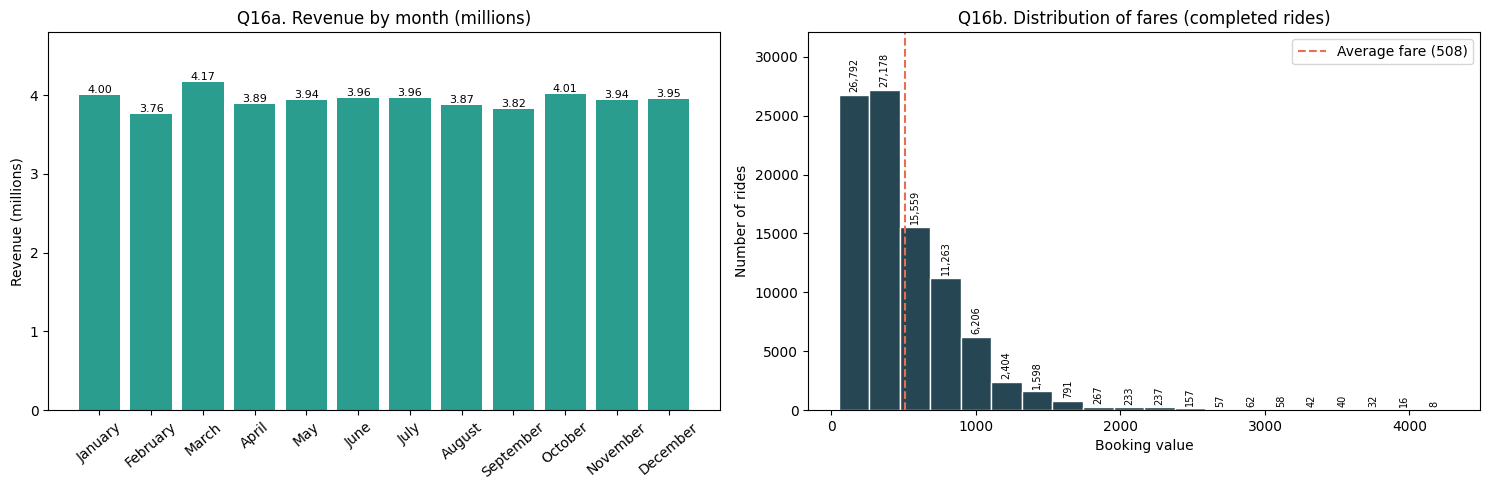

In [ ]:
#Question 16: What is the total revenue and the average fare?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Revenue counts completed rides only
completed = df[df["booking_status"] == "Completed"]

total_revenue = completed["booking_value"].sum()
print("Total revenue  :", f"{total_revenue:,.0f}")
print("Average fare   :", round(completed["booking_value"].mean(), 1))
print("Median fare    :", completed["booking_value"].median())
print("Lowest fare    :", completed["booking_value"].min())
print("Highest fare   :", completed["booking_value"].max())
print("Avg distance   :", round(completed["ride_distance"].mean(), 1), "km")
print("Revenue per km :", round(total_revenue / completed["ride_distance"].sum(), 2))
print("Revenue per day:", round(total_revenue / df["date"].nunique()))

# 2. Revenue by month, in millions
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
monthly = (completed.groupby("month_name")["booking_value"].sum() / 1_000_000).reindex(month_order).round(2)

# 3. Two charts: monthly revenue (left) and the spread of fares (right)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

bars = ax[0].bar(monthly.index, monthly.values, color="#2a9d8f")
ax[0].bar_label(bars, fmt="%.2f", fontsize=8)
ax[0].set_ylim(0, monthly.max() * 1.15)
ax[0].set_title("Q16a. Revenue by month (millions)")
ax[0].set_ylabel("Revenue (millions)")
ax[0].tick_params(axis="x", rotation=40)

counts, edges, patches = ax[1].hist(completed["booking_value"], bins=20, color="#264653", edgecolor="white")
ax[1].bar_label(patches, labels=[f"{int(c):,}" for c in counts], fontsize=7, rotation=90, padding=2)
ax[1].axvline(completed["booking_value"].mean(), color="#e76f51", linestyle="--",
              label=f"Average fare ({completed['booking_value'].mean():.0f})")
ax[1].set_ylim(0, counts.max() * 1.18)
ax[1].set_title("Q16b. Distribution of fares (completed rides)")
ax[1].set_xlabel("Booking value")
ax[1].set_ylabel("Number of rides")
ax[1].legend()

plt.tight_layout()
plt.show()

                rides     revenue  avg_fare  rides_%  revenue_%
payment_method                                                 
UPI             41834  21274591.0     508.5     45.0       45.0
Cash            23114  11756071.0     508.6     24.9       24.9
Uber Wallet     11206   5669070.0     505.9     12.0       12.0
Credit Card      9320   4753767.0     510.1     10.0       10.1
Debit Card       7526   3807075.0     505.9      8.1        8.1


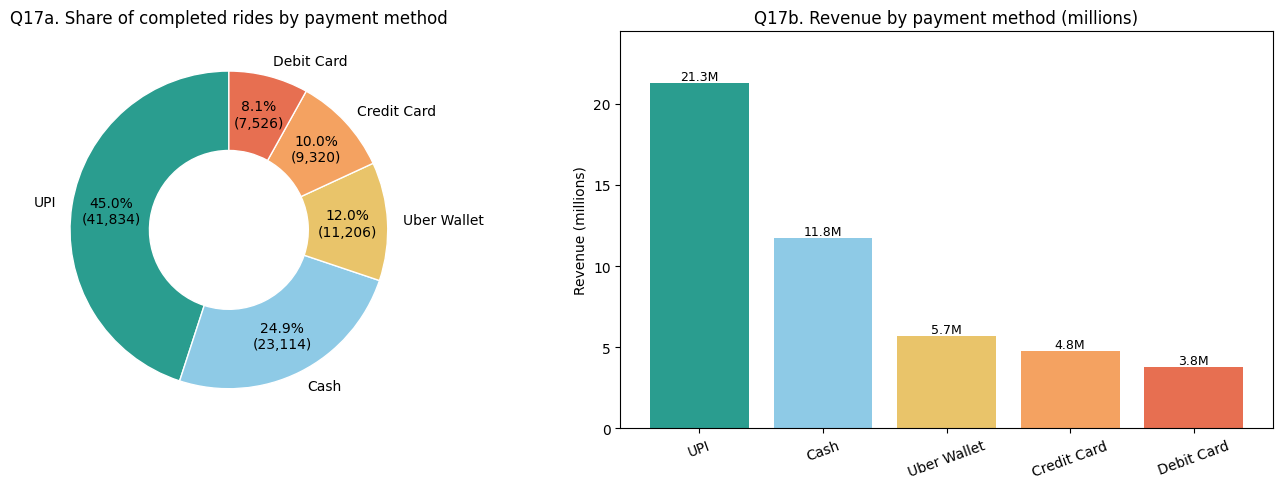

In [ ]:
#Question 17: Which payment method do customers use most?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Completed rides only (the only rows with a payment method)
completed = df[df["booking_status"] == "Completed"]

# 2. Rides, revenue and average fare for each payment method
pay = completed.groupby("payment_method").agg(
    rides=("booking_id", "count"),
    revenue=("booking_value", "sum"),
    avg_fare=("booking_value", "mean"),
)
pay["rides_%"] = (pay["rides"] / pay["rides"].sum() * 100).round(1)
pay["revenue_%"] = (pay["revenue"] / pay["revenue"].sum() * 100).round(1)
pay["avg_fare"] = pay["avg_fare"].round(1)
pay = pay.sort_values("rides", ascending=False)
print(pay)

# 3. Donut chart (share of rides) and bar chart (revenue)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#2a9d8f", "#8ecae6", "#e9c46a", "#f4a261", "#e76f51"]

ax[0].pie(pay["rides"], labels=pay.index, colors=colors, startangle=90,
          autopct=lambda p: f"{p:.1f}%\n({p * pay['rides'].sum() / 100:,.0f})",
          wedgeprops={"width": 0.5, "edgecolor": "white"}, pctdistance=0.75)
ax[0].set_title("Q17a. Share of completed rides by payment method")

rev_m = pay["revenue"] / 1_000_000
bars = ax[1].bar(pay.index, rev_m.values, color=colors)
ax[1].bar_label(bars, labels=[f"{v:.1f}M" for v in rev_m.values], fontsize=9)
ax[1].set_ylim(0, rev_m.max() * 1.15)
ax[1].set_title("Q17b. Revenue by payment method (millions)")
ax[1].set_ylabel("Revenue (millions)")
ax[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Correlation: 0.006
                rides  avg_fare
distance_group                 
0-10            15524     503.3
10-20           19220     506.6
20-30           19508     511.9
30-40           19500     506.9
40-50           19248     511.1


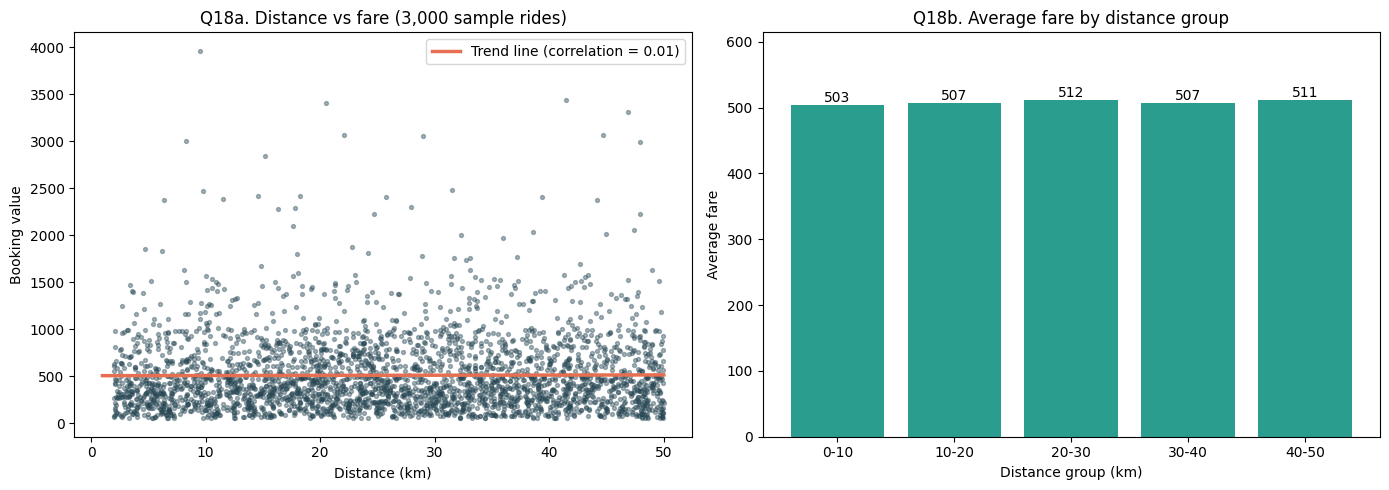

In [ ]:
# Question 18: Does a longer ride mean a higher fare?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

completed = df[df["booking_status"] == "Completed"].copy()

# 1. Correlation: a number from -1 to +1 showing how two columns move together
corr = completed["ride_distance"].corr(completed["booking_value"])
print("Correlation:", round(corr, 3))

# 2. Group rides into distance bands and compare average fare
completed["distance_group"] = pd.cut(completed["ride_distance"],
                                     bins=[0, 10, 20, 30, 40, 50],
                                     labels=["0-10", "10-20", "20-30", "30-40", "40-50"])
grp = completed.groupby("distance_group", observed=True).agg(
    rides=("booking_id", "count"),
    avg_fare=("booking_value", "mean"),
).round(1)
print(grp)

# 3. Scatter plot (3,000 random rides keeps it fast and readable) + trend line
sample = completed.sample(3000, random_state=42)
slope, intercept = np.polyfit(completed["ride_distance"], completed["booking_value"], 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(sample["ride_distance"], sample["booking_value"], s=8, alpha=0.4, color="#264653")
xs = np.linspace(1, 50, 50)
ax[0].plot(xs, slope * xs + intercept, color="#e76f51", linewidth=2.5,
           label=f"Trend line (correlation = {corr:.2f})")
ax[0].set_title("Q18a. Distance vs fare (3,000 sample rides)")
ax[0].set_xlabel("Distance (km)")
ax[0].set_ylabel("Booking value")
ax[0].legend()

bars = ax[1].bar(grp.index.astype(str), grp["avg_fare"], color="#2a9d8f")
ax[1].bar_label(bars, fmt="%.0f")
ax[1].set_ylim(0, grp["avg_fare"].max() * 1.2)
ax[1].set_title("Q18b. Average fare by distance group")
ax[1].set_xlabel("Distance group (km)")
ax[1].set_ylabel("Average fare")

plt.tight_layout()
plt.show()

Total customers    : 148788
One-time customers : 147582
Repeat customers   : 1206
Most bookings by one customer: 3
       customers  percent
count                    
1         147582    99.19
2           1200     0.81
3              6     0.00


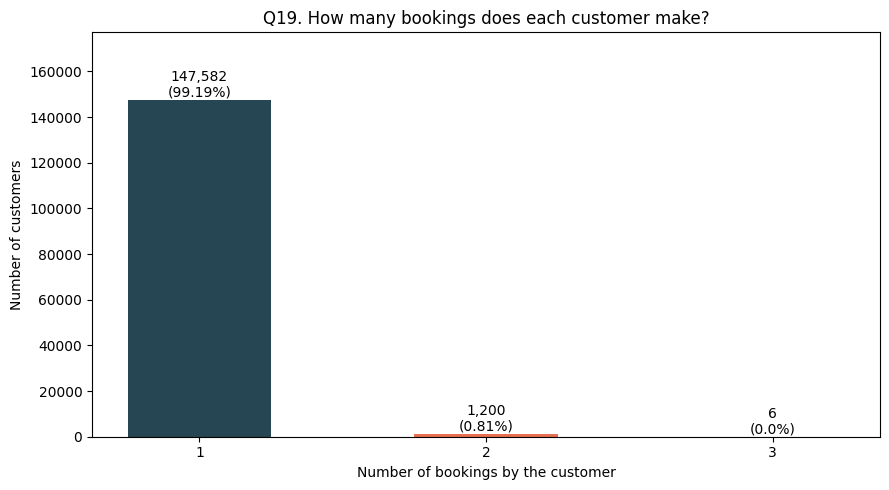

In [ ]:
# Question 19: Are customers repeat users or one-time users?
import pandas as pd
import matplotlib.pyplot as plt

# 1. Bookings per customer
per_customer = df["customer_id"].value_counts()

print("Total customers    :", len(per_customer))
print("One-time customers :", (per_customer == 1).sum())
print("Repeat customers   :", (per_customer > 1).sum())
print("Most bookings by one customer:", per_customer.max())

# 2. How many customers made 1 booking, 2 bookings, 3 bookings...
dist = per_customer.value_counts().sort_index()
dist_pct = (dist / dist.sum() * 100).round(2)
print(pd.DataFrame({"customers": dist, "percent": dist_pct}))

# 3. Bar chart with data labels
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(dist.index.astype(str), dist.values, color=["#264653", "#e76f51", "#e9c46a"], width=0.5)
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(dist.values, dist_pct.values)])
ax.set_ylim(0, dist.max() * 1.2)
ax.set_title("Q19. How many bookings does each customer make?")
ax.set_xlabel("Number of bookings by the customer")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

Avg customer rating: 4.4
Avg driver rating  : 4.23
Lowest rating given: 3.0 3.0
           customer  driver
3.0 - 3.4      4185    6694
3.5 - 3.9      8718   14327
4.0 - 4.4     33552   43901
4.5 - 5.0     46545   28078


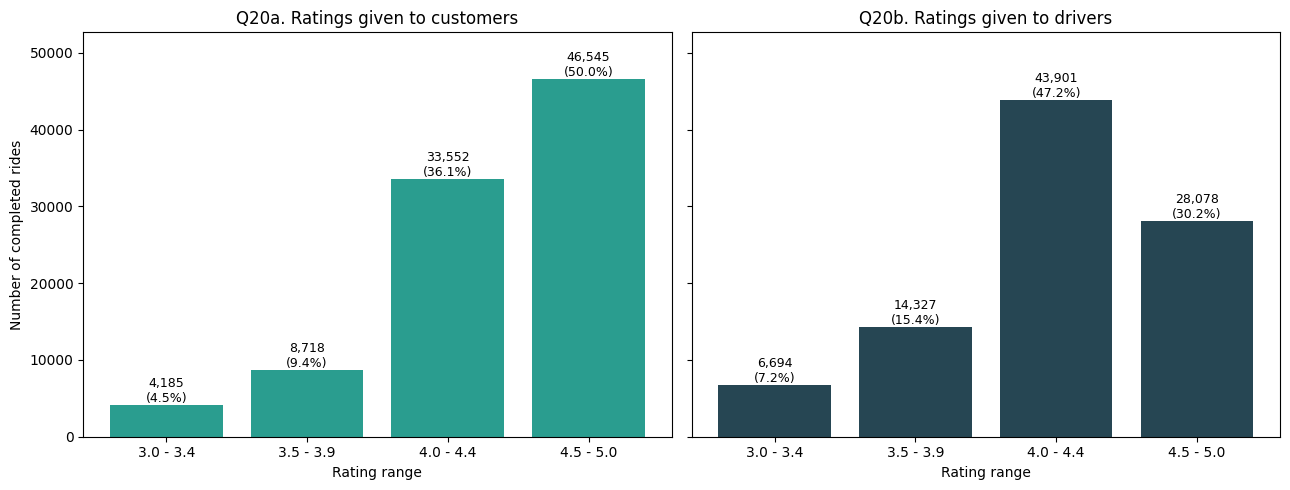

In [ ]:
#Question 20: What are the average customer and driver ratings?
import pandas as pd
import matplotlib.pyplot as plt

completed = df[df["booking_status"] == "Completed"]

# 1. Averages and lowest scores
print("Avg customer rating:", round(completed["customer_rating"].mean(), 2))
print("Avg driver rating  :", round(completed["driver_ratings"].mean(), 2))
print("Lowest rating given:", completed["customer_rating"].min(), completed["driver_ratings"].min())

# 2. Group the ratings into bands (ratings are decimals like 4.3, so we can't just count them)
bins = [3.0, 3.5, 4.0, 4.5, 5.01]
labels = ["3.0 - 3.4", "3.5 - 3.9", "4.0 - 4.4", "4.5 - 5.0"]
cust = pd.cut(completed["customer_rating"], bins=bins, labels=labels, right=False).value_counts().sort_index()
drv = pd.cut(completed["driver_ratings"], bins=bins, labels=labels, right=False).value_counts().sort_index()
print(pd.DataFrame({"customer": cust, "driver": drv}))

# 3. Two charts side by side, sharing the same y-axis so they are easy to compare
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for a, series, title, color in [(ax[0], cust, "Q20a. Ratings given to customers", "#2a9d8f"),
                                (ax[1], drv, "Q20b. Ratings given to drivers", "#264653")]:
    pct = (series / series.sum() * 100).round(1)
    bars = a.bar(series.index.astype(str), series.values, color=color)
    a.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(series.values, pct.values)], fontsize=9)
    a.set_ylim(0, series.max() * 1.2)
    a.set_title(title)
    a.set_xlabel("Rating range")

ax[0].set_ylabel("Number of completed rides")
plt.tight_layout()
plt.show()

               rides  customer_rating  driver_rating
vehicle_type                                        
Uber XL         2783             4.40           4.24
Bike           14034             4.40           4.23
Auto           23155             4.40           4.23
Go Mini        18549             4.40           4.23
Go Sedan       16676             4.41           4.23
Premier Sedan  11252             4.40           4.23
eBike           6551             4.40           4.23
Gap between best and worst -> driver: 0.01 | customer: 0.01


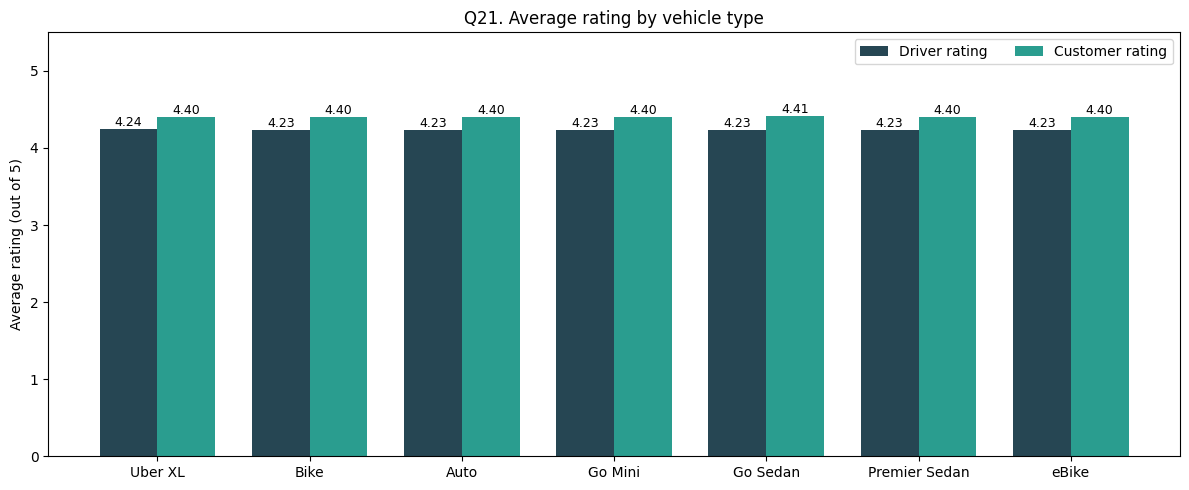

In [ ]:
# Question 21: Do ratings differ by vehicle type?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

completed = df[df["booking_status"] == "Completed"]

# 1. Average ratings for each vehicle type
ratings = completed.groupby("vehicle_type").agg(
    rides=("booking_id", "count"),
    customer_rating=("customer_rating", "mean"),
    driver_rating=("driver_ratings", "mean"),
).round(2)
ratings = ratings.sort_values("driver_rating", ascending=False)
print(ratings)

gap_driver = ratings["driver_rating"].max() - ratings["driver_rating"].min()
gap_customer = ratings["customer_rating"].max() - ratings["customer_rating"].min()
print("Gap between best and worst -> driver:", round(gap_driver, 2), "| customer:", round(gap_customer, 2))

# 2. Grouped bar chart. The y-axis starts at 0, so the bars are not exaggerated.
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(ratings)); w = 0.38
b1 = ax.bar(x - w/2, ratings["driver_rating"], w, color="#264653", label="Driver rating")
b2 = ax.bar(x + w/2, ratings["customer_rating"], w, color="#2a9d8f", label="Customer rating")
ax.bar_label(b1, fmt="%.2f", fontsize=9)
ax.bar_label(b2, fmt="%.2f", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(ratings.index)
ax.set_ylim(0, 5.5)
ax.set_title("Q21. Average rating by vehicle type")
ax.set_ylabel("Average rating (out of 5)")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

Pickup locations: 176
Drop locations  : 176
Average bookings per pickup location: 852
pickup_location
Khandsa             949
Barakhamba Road     946
Saket               931
Badarpur            921
Pragati Maidan      920
Madipur             919
AIIMS               918
Mehrauli            915
Dwarka Sector 21    914
Pataudi Chowk       907
Name: count, dtype: int64
drop_location
Ashram                936
Basai Dhankot         917
Lok Kalyan Marg       916
Narsinghpur           913
Cyber Hub             912
Kalkaji               912
Kashmere Gate ISBT    909
Udyog Vihar           906
Lajpat Nagar          904
Madipur               902
Name: count, dtype: int64


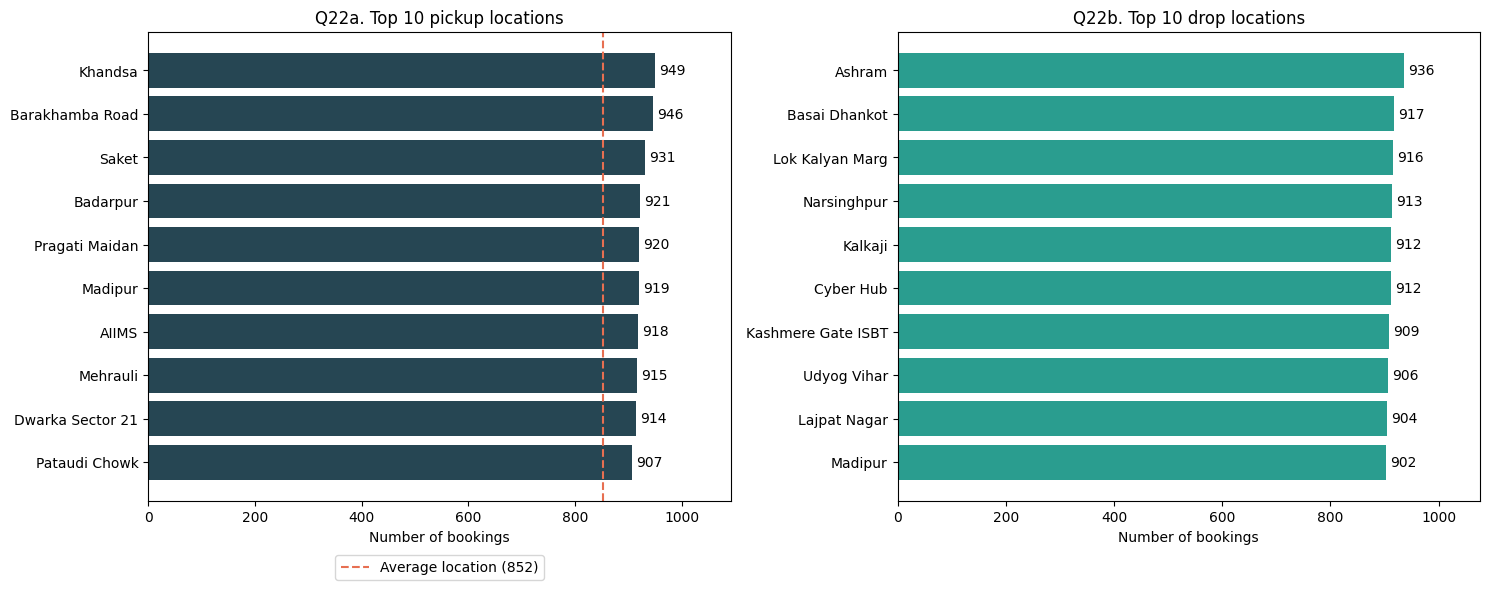

In [ ]:
# Question 22: Which pickup and drop locations are busiest?
import pandas as pd
import matplotlib.pyplot as plt

# 1. How many locations are there?
print("Pickup locations:", df["pickup_location"].nunique())
print("Drop locations  :", df["drop_location"].nunique())

# 2. Top 10 of each, and the average for comparison
top_pickup = df["pickup_location"].value_counts().head(10)
top_drop = df["drop_location"].value_counts().head(10)
avg_pickup = len(df) / df["pickup_location"].nunique()
print("Average bookings per pickup location:", round(avg_pickup))
print(top_pickup)
print(top_drop)

# 3. Two horizontal bar charts with data labels
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

for a, s, title, color in [(ax[0], top_pickup, "Q22a. Top 10 pickup locations", "#264653"),
                           (ax[1], top_drop, "Q22b. Top 10 drop locations", "#2a9d8f")]:
    s = s.sort_values()                      # biggest bar at the top
    bars = a.barh(s.index, s.values, color=color)
    a.bar_label(bars, labels=[f"{v:,}" for v in s.values], padding=3)
    a.set_xlim(0, s.max() * 1.15)
    a.set_title(title)
    a.set_xlabel("Number of bookings")

# dashed line = average location, so we can see how much the "top" really stands out
ax[0].axvline(avg_pickup, color="#e76f51", linestyle="--", label=f"Average location ({avg_pickup:.0f})")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.show()

                      bookings  completion_rate
pickup_location                                
Vinobapuri                 823             54.7
Akshardham                 839             56.1
Chhatarpur                 829             58.1
Badshahpur                 868             58.3
Pragati Maidan             920             58.5
Netaji Subhash Place       830             58.7
Vatika Chowk               833             58.7
Faridabad Sector 15        831             58.7
Indirapuram                854             58.9
IFFCO Chowk                830             59.2
                 bookings  completion_rate
pickup_location                           
Jama Masjid           849             64.3
Anand Vihar           859             64.4
Laxmi Nagar           797             64.4
Subhash Nagar         861             64.5
Sushant Lok           850             64.6
RK Puram              850             64.7
IMT Manesar           840             64.8
Yamuna Bank           824            

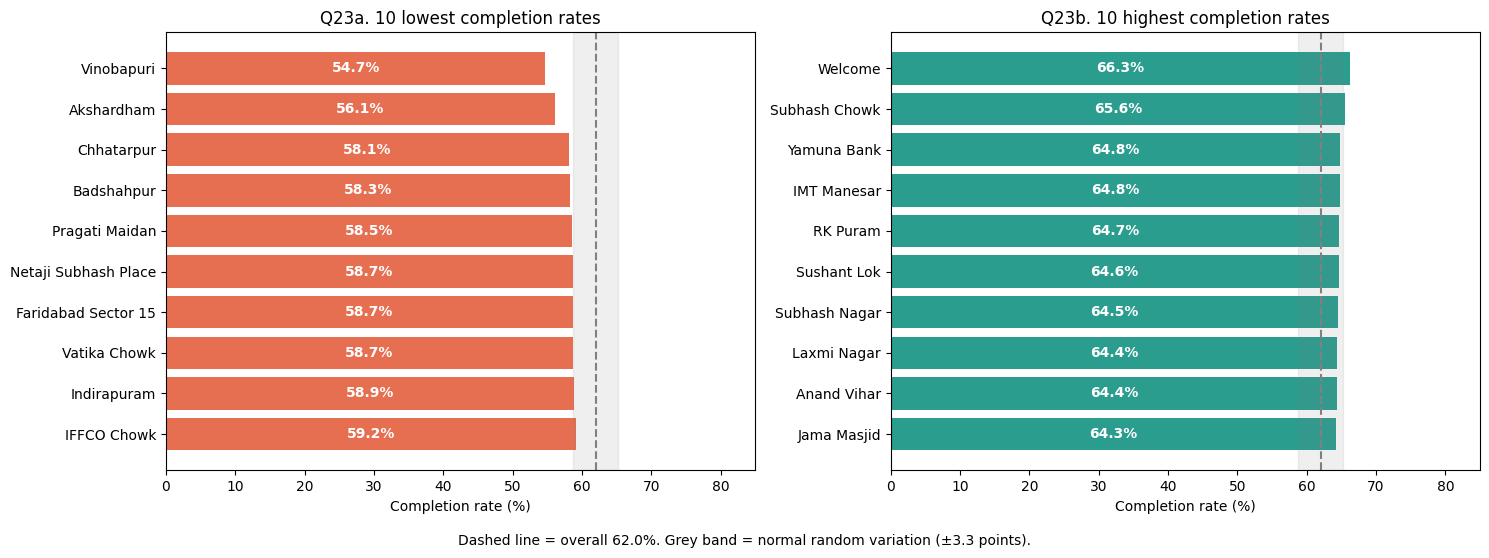

In [ ]:
# Question 23: Which pickup areas have the lowest completion rates?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df["completed"] = df["booking_status"] == "Completed"
overall = df["completed"].mean() * 100

# 1. Completion rate for each pickup location
loc = df.groupby("pickup_location").agg(
    bookings=("booking_id", "count"),
    completion_rate=("completed", "mean"),
)
loc["completion_rate"] = (loc["completion_rate"] * 100).round(1)
loc = loc.sort_values("completion_rate")

worst10 = loc.head(10)
best10 = loc.tail(10)
print(worst10)
print(best10)

# 2. How much variation is just chance? (95% margin of error for a typical location)
avg_n = loc["bookings"].mean()
margin = 1.96 * np.sqrt(overall / 100 * (1 - overall / 100) / avg_n) * 100
inside = ((loc["completion_rate"] >= overall - margin) &
          (loc["completion_rate"] <= overall + margin)).mean() * 100
print(f"Normal random variation: +/- {margin:.1f} points")
print(f"Locations inside that band: {inside:.1f}%")

# 3. Charts: lowest 10 (left) and highest 10 (right), with the "chance" band in grey
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)

for a, d, title, color, asc in [(ax[0], worst10, "Q23a. 10 lowest completion rates", "#e76f51", False),
                                (ax[1], best10, "Q23b. 10 highest completion rates", "#2a9d8f", True)]:
    d = d.sort_values("completion_rate", ascending=asc)     # puts the extreme one at the top
    bars = a.barh(d.index, d["completion_rate"], color=color)
    a.bar_label(bars, labels=[f"{v:.1f}%" for v in d["completion_rate"]],
                label_type="center", color="white", fontweight="bold")
    a.axvline(overall, color="gray", linestyle="--")
    a.axvspan(overall - margin, overall + margin, color="gray", alpha=0.12)
    a.set_title(title)
    a.set_xlabel("Completion rate (%)")

ax[0].set_xlim(0, 85)
fig.text(0.5, 0.0, f"Dashed line = overall {overall:.1f}%. Grey band = normal random variation (±{margin:.1f} points).",
         ha="center", fontsize=10)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

Completed rides : 93000
Unique routes   : 29269
                                      rides  revenue  avg_fare
route                                                         
Nirman Vihar -> Vatika Chowk              5   9284.0    1856.8
Ashok Vihar -> Basai Dhankot              9   9280.0    1031.1
Anand Vihar ISBT -> Noida Film City       7   8960.0    1280.0
Ambience Mall -> Akshardham              11   8518.0     774.4
Cyber Hub -> Gurgaon Railway Station      9   8396.0     932.9
Greater Noida -> Jor Bagh                 8   8252.0    1031.5
Noida Extension -> Vaishali               8   8202.0    1025.2
Greater Noida -> Rithala                  7   8082.0    1154.6
Udyog Vihar -> Tagore Garden              9   7940.0     882.2
Cyber Hub -> Chanakyapuri                 7   7900.0    1128.6
                                    rides  revenue  avg_fare
route                                                       
Rohini West -> Sohna Road              13   6204.0     477.2
DLF City Cour

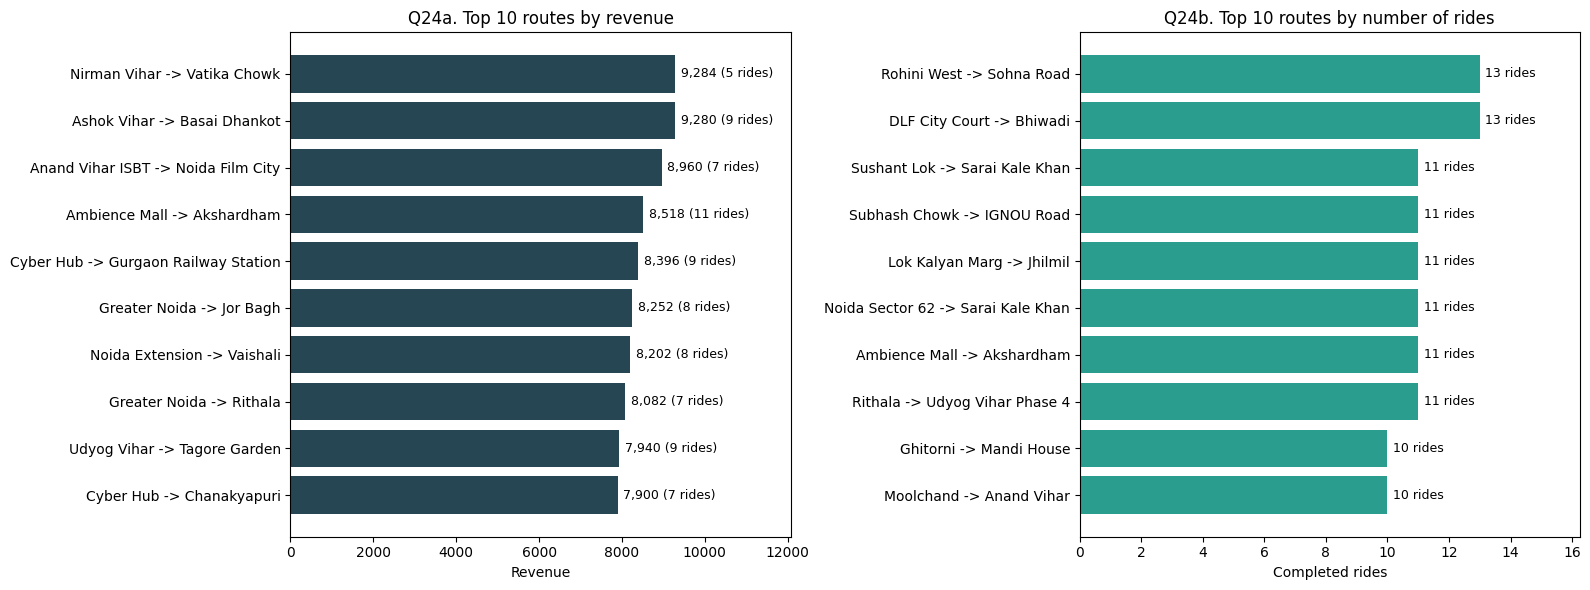

In [ ]:
# Question 24: Which routes earn the most?
import pandas as pd
import matplotlib.pyplot as plt

completed = df[df["booking_status"] == "Completed"].copy()

# 1. Join pickup and drop into one "route" column
completed["route"] = completed["pickup_location"] + " -> " + completed["drop_location"]
print("Completed rides :", len(completed))
print("Unique routes   :", completed["route"].nunique())

# 2. Rides, revenue and average fare for each route
routes = completed.groupby("route").agg(
    rides=("booking_id", "count"),
    revenue=("booking_value", "sum"),
)
routes["avg_fare"] = (routes["revenue"] / routes["rides"]).round(1)

top_revenue = routes.sort_values("revenue", ascending=False).head(10)
top_rides = routes.sort_values(["rides", "revenue"], ascending=False).head(10)
print(top_revenue)
print(top_rides)

# 3. How concentrated is the business on its best routes?
total_revenue = completed["booking_value"].sum()
print("Top 10 routes share of revenue:", round(top_revenue["revenue"].sum() / total_revenue * 100, 2), "%")
print("Routes with only 1 ride:", round((routes["rides"] == 1).mean() * 100, 1), "%")
print("Most rides on any route:", routes["rides"].max())

# 4. Two charts: top by revenue (left) and top by number of rides (right)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

t = top_revenue.sort_values("revenue")
bars = ax[0].barh(t.index, t["revenue"], color="#264653")
ax[0].bar_label(bars, labels=[f"{v:,.0f} ({n} rides)" for v, n in zip(t["revenue"], t["rides"])],
                padding=4, fontsize=9)
ax[0].set_xlim(0, t["revenue"].max() * 1.3)
ax[0].set_title("Q24a. Top 10 routes by revenue")
ax[0].set_xlabel("Revenue")

t2 = top_rides.sort_values("rides")
bars2 = ax[1].barh(t2.index, t2["rides"], color="#2a9d8f")
ax[1].bar_label(bars2, labels=[f"{n} rides" for n in t2["rides"]], padding=4, fontsize=9)
ax[1].set_xlim(0, t2["rides"].max() * 1.25)
ax[1].set_title("Q24b. Top 10 routes by number of rides")
ax[1].set_xlabel("Completed rides")

plt.tight_layout()
plt.show()